In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

In [2]:
import re

# Function to read and parse LAMMPS log
def parse_lammps_log(file_path):
    data = {'Step': [], 'Temp': [], 'TotEng': [], 'Press': [], 'Volume': [], 'v_nNa': []}

    with open(file_path, 'r') as file:
        for line in file:
            # Find thermo output section
            if re.match(r"^\s*Step\s+Temp\s+TotEng", line):
                # Skip header lines
                next(file)
                # Parse the actual data lines
                for data_line in file:
                    if re.match(r"^\s*\d+", data_line):
                        # Extract values (Assuming specific columns order here)
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['Temp'].append(float(values[1]))
                        data['TotEng'].append(float(values[2]))
                        data['Press'].append(float(values[3]))
                        data['Volume'].append(float(values[4]))
                        data['v_nNa'].append(float(values[5]))
                    else:
                        break
    return data

In [3]:
# Path to your LAMMPS log file
log_file_path = 'gcmc_1.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)

E_Na = -.13023100E+01
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

IndexError: list index out of range

In [4]:
# Path to your LAMMPS log file
log_file_path = 'gcmc_2.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)

E_Na = -.13023100E+01
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

IndexError: list index out of range

ZeroDivisionError: float division by zero

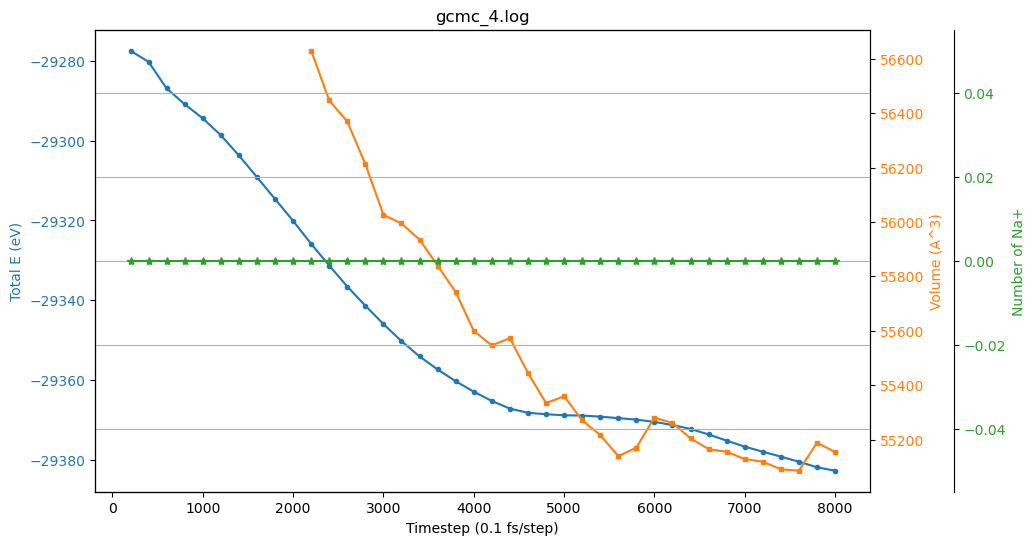

In [6]:
# Path to your LAMMPS log file
log_file_path = 'gcmc_4.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)

E_Na = -.13023100E+01
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

Text(0.5, 1.0, './pot_save/gcmc_230.log')

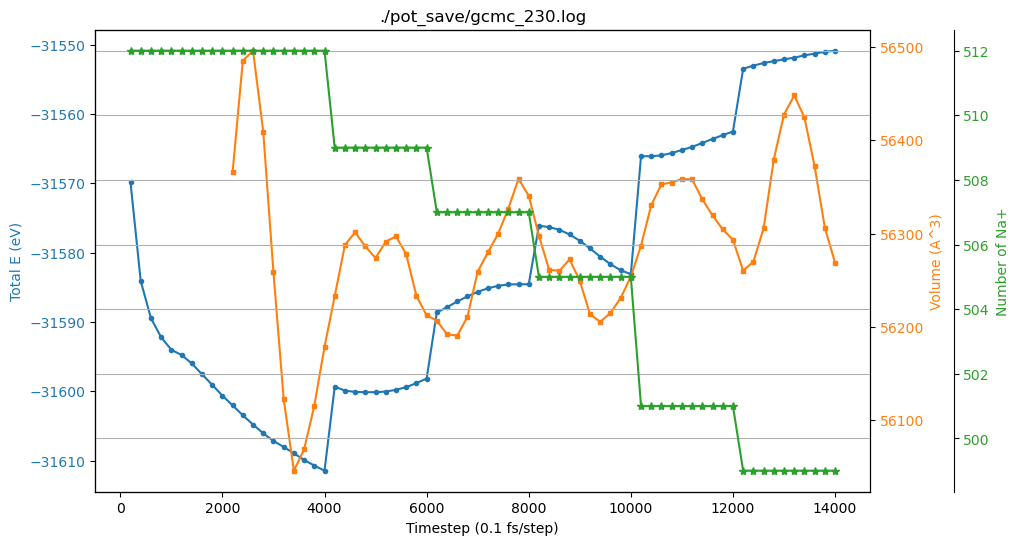

In [25]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_230.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


Text(0.5, 1.0, './pot_save/gcmc_231.log')

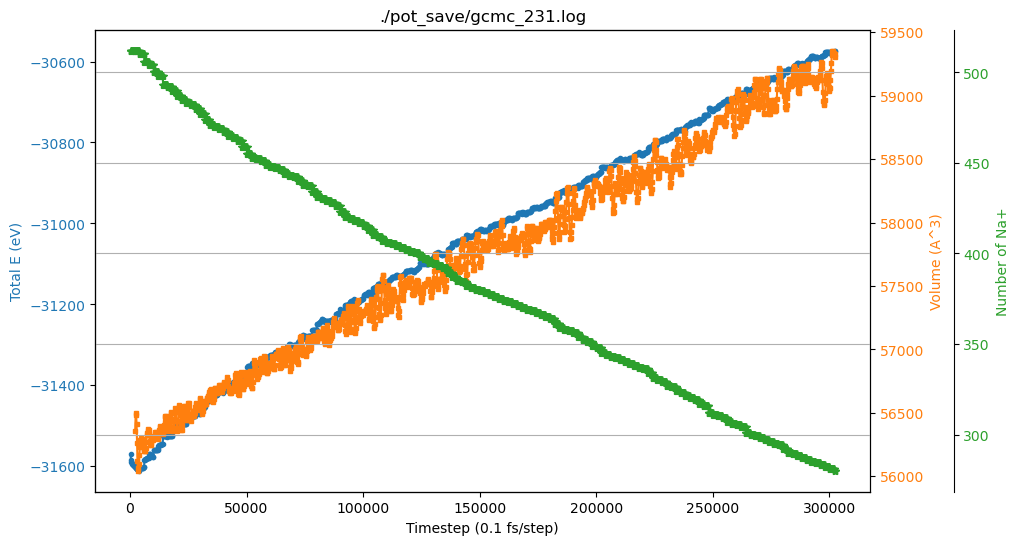

In [22]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_231.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


Text(0.5, 1.0, './pot_save/gcmc_235.log')

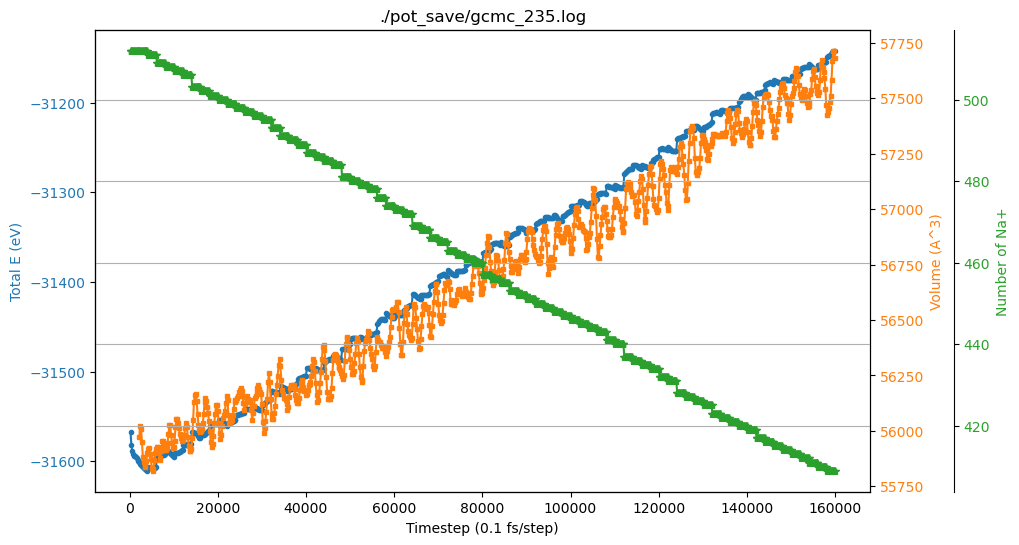

In [19]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_235.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


Text(0.5, 1.0, './pot_save/gcmc_257.log')

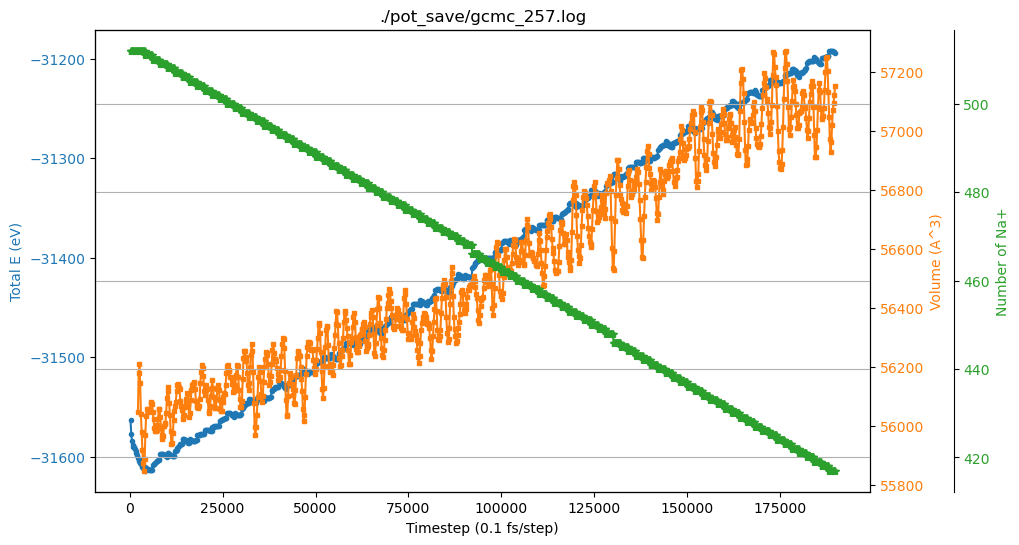

In [5]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_257.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


Text(0.5, 1.0, './pot_save/gcmc_274.log')

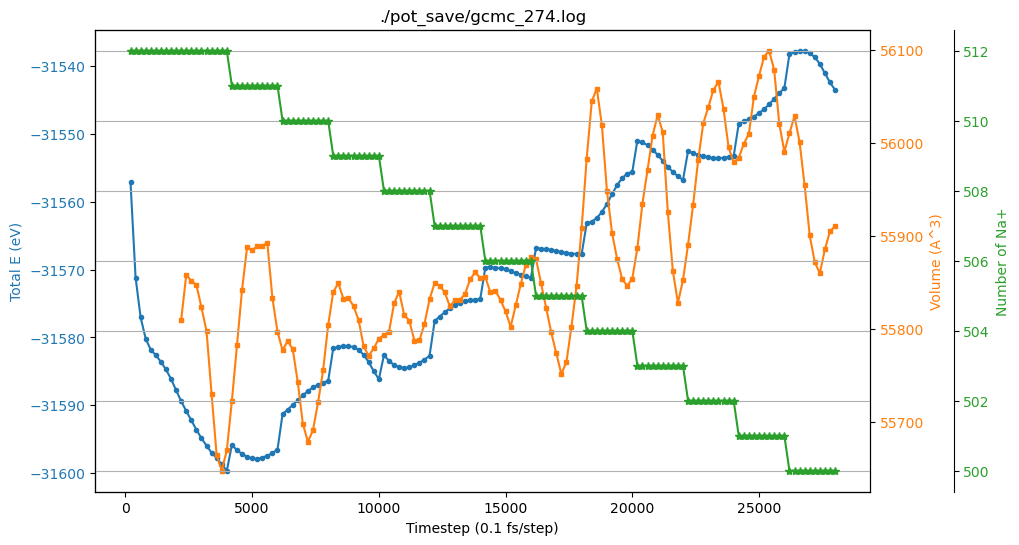

In [7]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_274.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


Text(0.5, 1.0, './pot_save/gcmc_279.log')

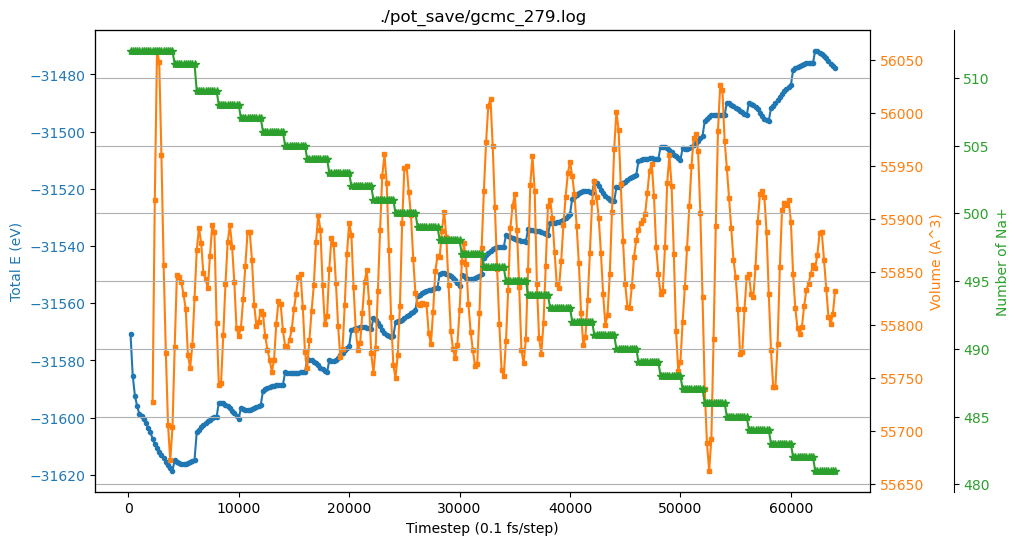

In [5]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_279.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


Text(0.5, 1.0, './pot_save/gcmc_288.log')

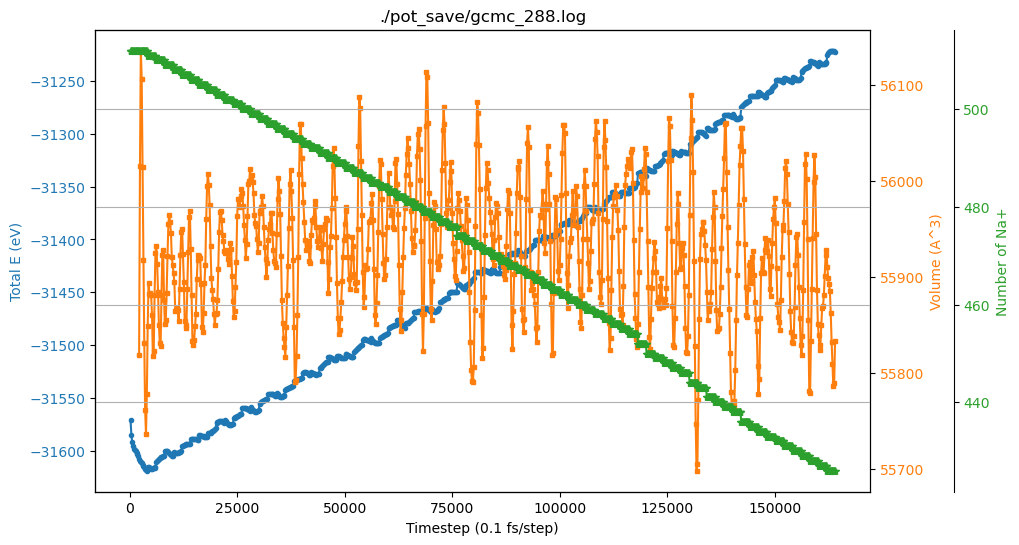

In [23]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_288.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


Text(0.5, 1.0, './pot_save/gcmc_321.log')

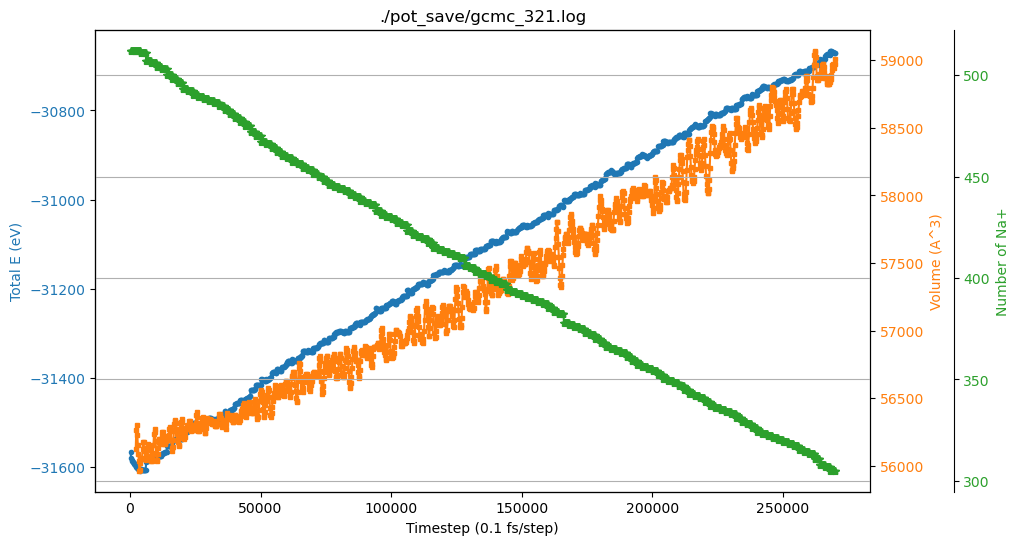

In [6]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_321.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


Text(0.5, 1.0, './pot_save/gcmc_331.log')

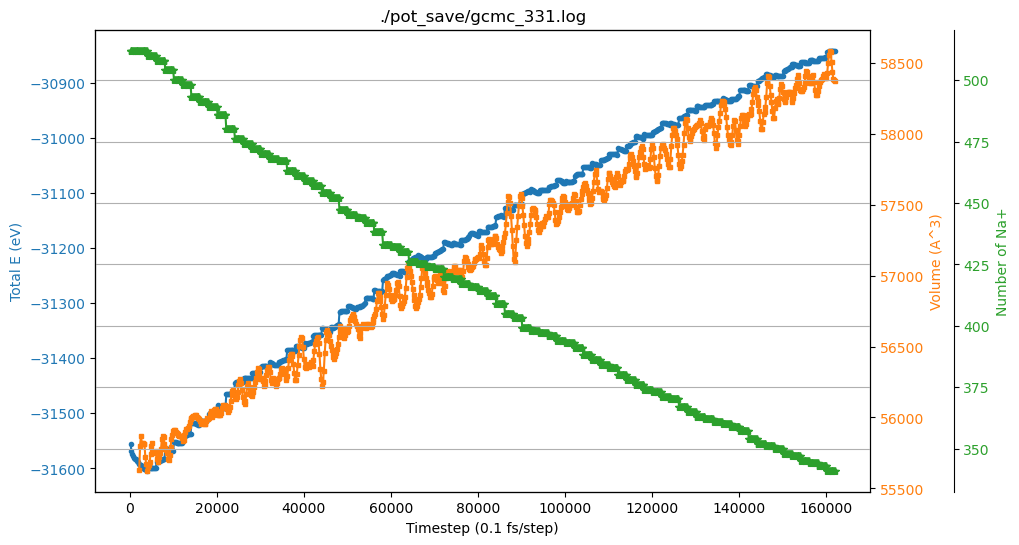

In [4]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_331.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


Text(0.5, 1.0, './pot_save/gcmc_332.log')

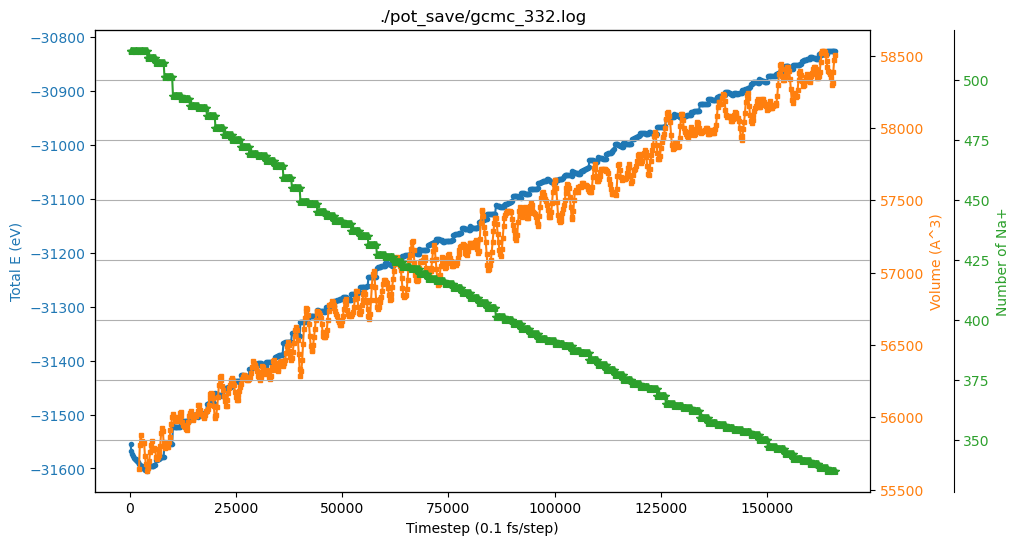

In [5]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_332.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


3.1448442168674773

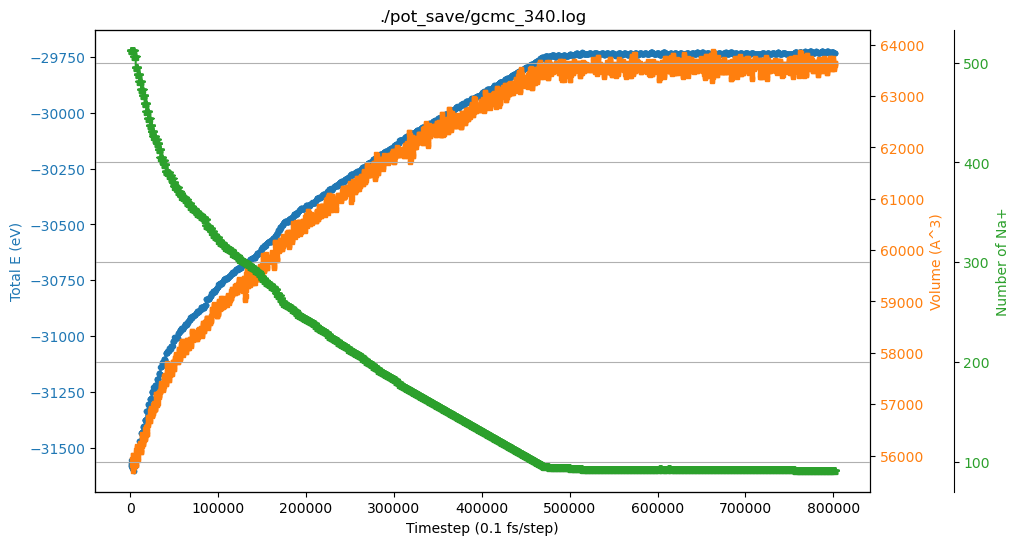

In [5]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_340.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)


E_Na = -.13023100E+01
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

3.140461929824561

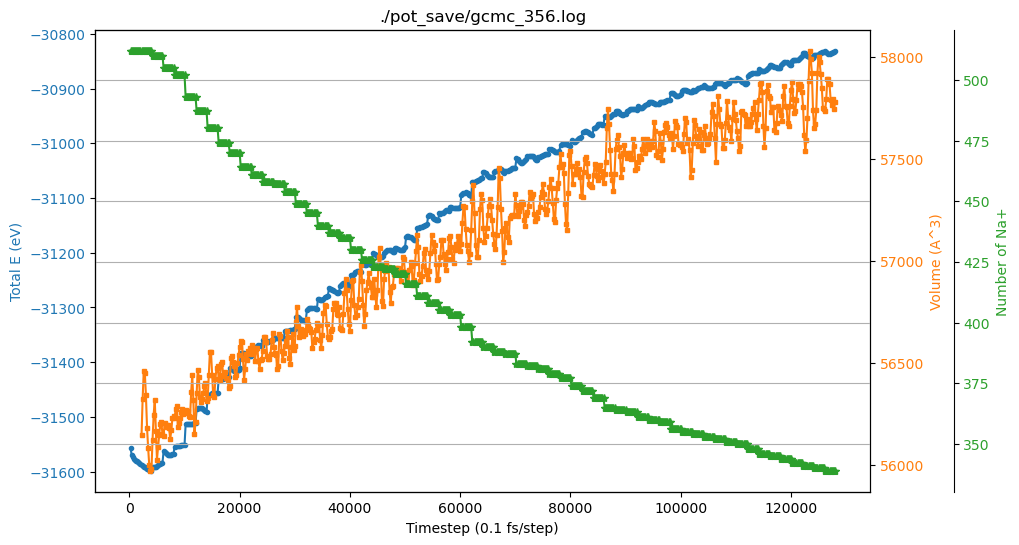

In [12]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_356.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)

E_Na = -.13023100E+01
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

3.071689999999926

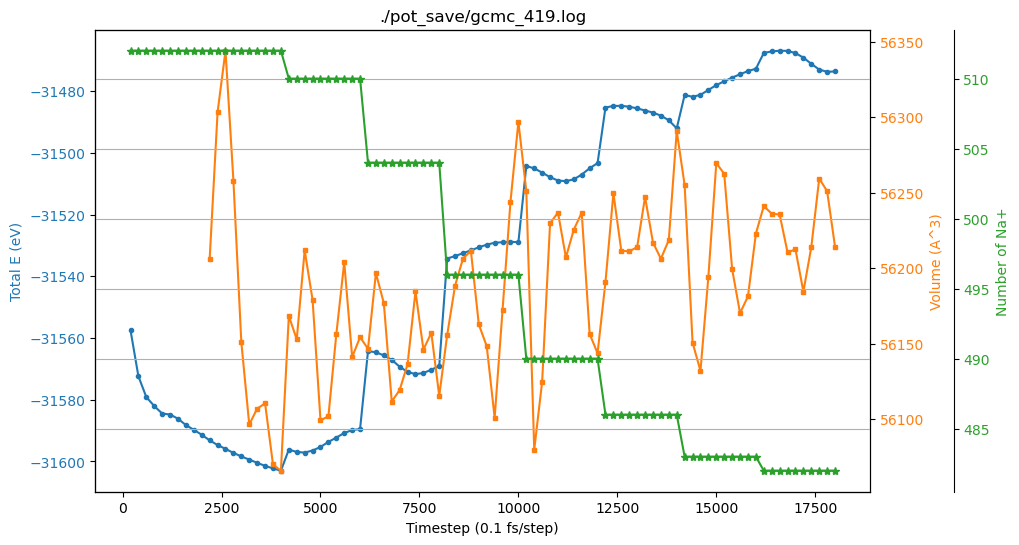

In [5]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_419.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)

E_Na = -.13023100E+01
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave



In [5]:
E_Na = -0.14023
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

4.532221612903153

In [8]:
E_Na = -0.14023
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

4.302541929824561

In [4]:
E_Na = -0.14023
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

4.315426976744205

In [14]:
log_data['v_nNa'][-1]

426.0

In [15]:
x = int((log_data['Step'][-1]-5000)/4000)
a = range(0,x*20,20)

In [16]:
len(a)

19

In [17]:
i=1
log_data['Step'][a[i]-1], log_data['Step'][a[i+1]-1]

(4000, 8000)

In [18]:
i
log_data['v_nNa'][a[i]] - log_data['v_nNa'][a[i+1]]

6.0

In [13]:
x = int((log_data['Step'][-1]-5000)/4000)
a = range(0,x*20,20)
V = []
E_Na = -.13023100E+01

for i in range(len(a)-1):
    delta_Na = log_data['v_nNa'][a[i]] - log_data['v_nNa'][a[i+1]]
    delta_E =  log_data['TotEng'][a[i]-1] - log_data['TotEng'][a[i+1]-1]
    V.append(-(delta_E-delta_Na*E_Na)/delta_Na)

In [14]:
V

[-384.6928099999995,
 2.5429399999998505,
 2.4490233333333626,
 2.96376692307684,
 3.1662900000001515,
 5.36519000000017,
 2.5259399999995704,
 2.304578888888837,
 4.352940000000251,
 1.1525471428573009,
 5.51611857142848,
 3.4986899999994763,
 1.1646900000001486,
 4.713856666666323,
 2.088118571428596,
 5.422689999999909,
 1.6933566666669966,
 3.619089999999994,
 2.0020233333334887,
 1.5986900000002036,
 2.710689999999738,
 6.551089999999965,
 0.9356899999999806,
 4.05219000000128,
 3.148939999999163,
 5.585190000000727,
 -0.5848099999993452,
 0.6230233333326737,
 8.158023333333741]

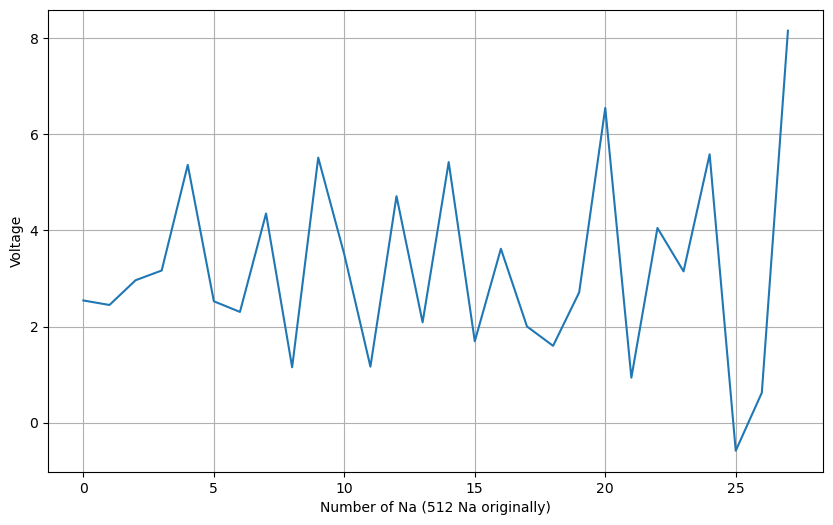

In [20]:
fig = plt.figure(figsize=(10, 6))

plt.plot(range(len(V)-1), V[1:])
#plt.xlim(40,300)
plt.ylabel('Voltage')
plt.xlabel('Number of Na (512 Na originally)')
plt.title('')
plt.grid()
#plt.text(50,5, f'Average V = {round(np.mean(V[5:50]),3)}')
#plt.xlim(512,480)
#plt.savefig('desodiation_V.png', dpi=300, bbox_inches='tight')

In [21]:
np.mean(V[1:])

3.190020241583852

In [15]:
log_data['TotEng'][20],log_data['TotEng'][-1],log_data['v_nNa'][20],log_data['v_nNa'][-1]

(-31591.343, -30831.629, 510.0, 339.0)